# Assignment 1: Post-Results Analysis

**Performed by**
- Võ Thị Như Quỳnh (2353041)
- Mai Trung Kiên (2352641)
- Hứa Tuệ Minh (2450018)

Continue from `02_results.ipynb`. Sections 1–3 reuse the 25 main runs (five models × seeds 42–46): five-seed errors, robustness and interpretability. Sections 4–6 compare the extension runs, trained by the same `train.py` and evaluated by `evaluate.py` with the same protocol and saved in `outputs/`. Section 7 summarizes. This notebook trains nothing. It saves the robustness scores once in `outputs/robustness_scores.csv`, so later runs skip that step. Run from `Assignment1/` or the repository root.

In [1]:
import json
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

ROOT = Path.cwd()
if ROOT.name != "Assignment1":
    ROOT = ROOT / "Assignment1"
sys.path.insert(0, str(ROOT))
from data_loader import read_fashion_mnist
from models.linear import LinearClassifier
from models.mlp import MLP
from models.cnn import CNN
from models.lstm import LSTMClassifier, LSTMColumns
from models.transformer import TransformerClassifier, TransformerPatch7, TransformerRows
from models.gru import GRUClassifier
from models.augmented import AugmentedLinear, AugmentedMLP, AugmentedCNN, AugmentedLSTM, AugmentedTransformer

NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
MODELS = ["Linear", "MLP", "CNN", "LSTM", "Transformer"]
CLASSES = {"Linear": LinearClassifier, "MLP": MLP, "CNN": CNN, "LSTM": LSTMClassifier, "Transformer": TransformerClassifier,
           "GRU": GRUClassifier, "LSTMColumns": LSTMColumns, "TransformerPatch7": TransformerPatch7, "TransformerRows": TransformerRows,
           "AugmentedLinear": AugmentedLinear, "AugmentedMLP": AugmentedMLP, "AugmentedCNN": AugmentedCNN,
           "AugmentedLSTM": AugmentedLSTM, "AugmentedTransformer": AugmentedTransformer}
SEEDS = (42, 43, 44, 45, 46)
UPPER_BODY = [0, 2, 4, 6]   #t-shirt/top, pullover, coat, shirt
FOOTWEAR = [5, 7, 9]        #sandal, sneaker, ankle boot
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# later folder names hold the later run for the same model and seed
runs = {}
for path in sorted((ROOT / "outputs").glob("*/metrics.json")):
    result = json.loads(path.read_text())
    result["folder"] = path.parent
    runs[result["model"], result["seed"]] = result
predictions = {}
for name in MODELS:
    for seed in SEEDS:
        with np.load(runs[name, seed]["folder"] / "test_predictions.npz") as saved:
            predictions[name, seed] = {key: saved[key] for key in saved.files}
_, _, test_images, test_labels = read_fashion_mnist()
pixels = test_images.astype(np.float32) / np.float32(255)

def load_model(name, seed):
    saved = torch.load(runs[name, seed]["folder"] / "best.pt", map_location="cpu", weights_only=True)
    model = CLASSES[name]()
    model.load_state_dict(saved["model_state"])
    return model.eval(), saved["data"]["mean"], saved["data"]["std"]

def normalize(images, mean, std):
    return torch.from_numpy((images - np.float32(mean)) / np.float32(std)).unsqueeze(1)

def pm(values, digits=2):
    return f"{np.mean(values):.{digits}f} ± {np.std(values, ddof=1):.{digits}f}"

pd.Series({"runs": len(predictions), "test images": len(test_labels)})

runs              25
test images    10000
dtype: int64

## 1. Five-seed test errors

`02_results.ipynb` shows confusion matrices, per-class F1 and errors for seed 42 only. Here every value is aggregated over seeds 42–46: mean ± sample standard deviation.

In [3]:
class_f1 = {name: np.array([f1_score(predictions[name, s]["labels"], predictions[name, s]["predictions"],
                                    labels=range(10), average=None) for s in SEEDS]) for name in MODELS}
display(pd.DataFrame({name: [pm(scores[:, k], 3) for k in range(10)] for name, scores in class_f1.items()}, index=NAMES))
weakest = {(name, s): NAMES[int(np.argmin(scores[i]))] for name, scores in class_f1.items() for i, s in enumerate(SEEDS)}
print("Weakest class in each of the 25 runs:", set(weakest.values()))

,Linear,MLP,CNN,LSTM,Transformer
T-shirt/top,0.804 ± 0.006,0.838 ± 0.006,0.866 ± 0.003,0.817 ± 0.006,0.819 ± 0.007
Trouser,0.967 ± 0.002,0.981 ± 0.002,0.986 ± 0.002,0.975 ± 0.002,0.977 ± 0.001
Pullover,0.724 ± 0.009,0.806 ± 0.007,0.860 ± 0.007,0.805 ± 0.010,0.788 ± 0.014
Dress,0.848 ± 0.005,0.890 ± 0.005,0.912 ± 0.004,0.880 ± 0.005,0.876 ± 0.004
Coat,0.746 ± 0.005,0.815 ± 0.006,0.860 ± 0.005,0.804 ± 0.007,0.787 ± 0.013
Sandal,0.928 ± 0.004,0.961 ± 0.006,0.977 ± 0.005,0.965 ± 0.005,0.961 ± 0.003
Shirt,0.599 ± 0.009,0.712 ± 0.008,0.751 ± 0.007,0.679 ± 0.008,0.650 ± 0.013
Sneaker,0.919 ± 0.004,0.947 ± 0.006,0.961 ± 0.006,0.950 ± 0.005,0.940 ± 0.003
Bag,0.937 ± 0.002,0.972 ± 0.002,0.983 ± 0.001,0.970 ± 0.002,0.956 ± 0.004
Ankle boot,0.943 ± 0.003,0.956 ± 0.004,0.970 ± 0.004,0.964 ± 0.003,0.953 ± 0.003


Weakest class in each of the 25 runs: {'Shirt'}


**Observation.** Shirt is the weakest class in all 25 runs: mean F1 ranges from **0.599** (Linear) to **0.751** (CNN). Trouser is the easiest class, with F1 from 0.967 to 0.986. CNN has the highest mean F1 for all ten classes. Standard deviations are at most 0.014, so the seed-42 per-class scores were representative.
- **Link to the EDA.** Shirt is in three of the five closest class-mean pairs (Pullover 0.096, Coat 0.107, T-shirt/top 0.132). In t-SNE, Shirt mixes with the other upper-body classes, and Trouser forms a compact group.

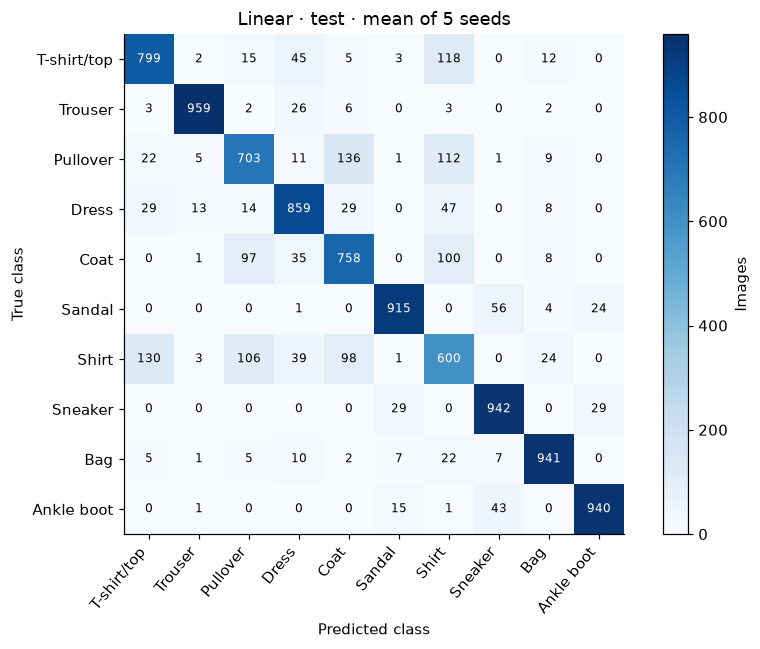

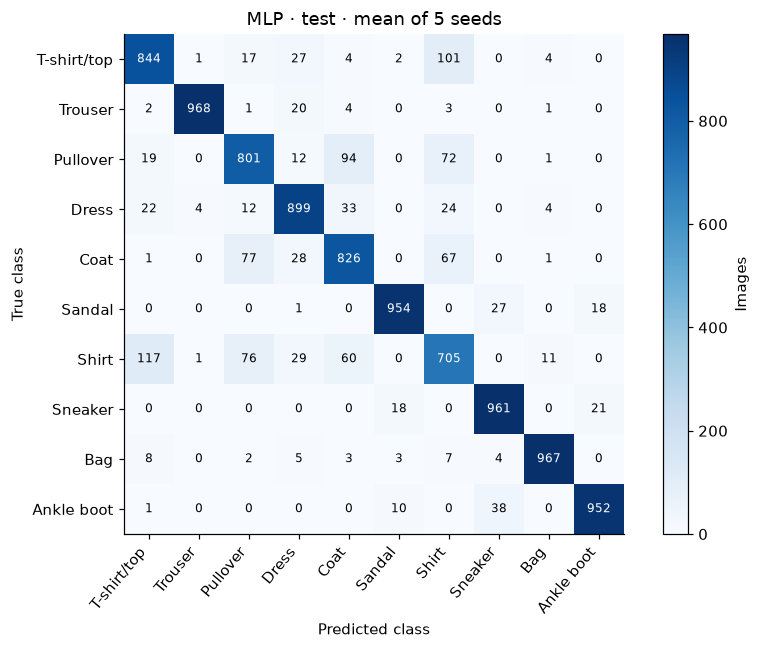

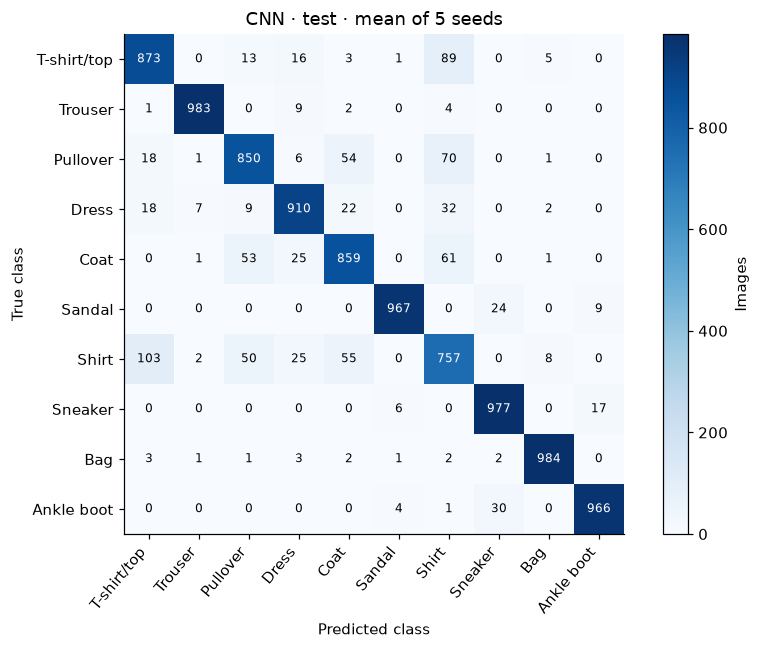

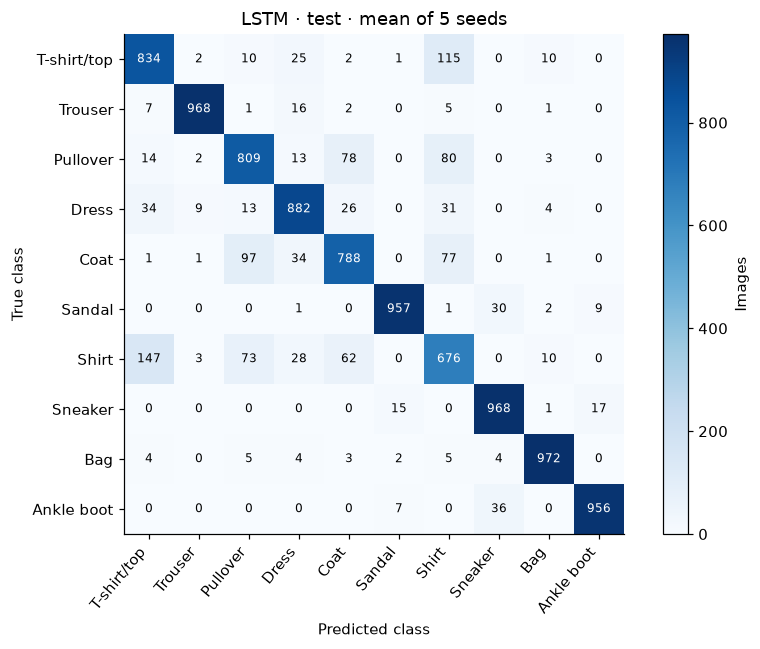

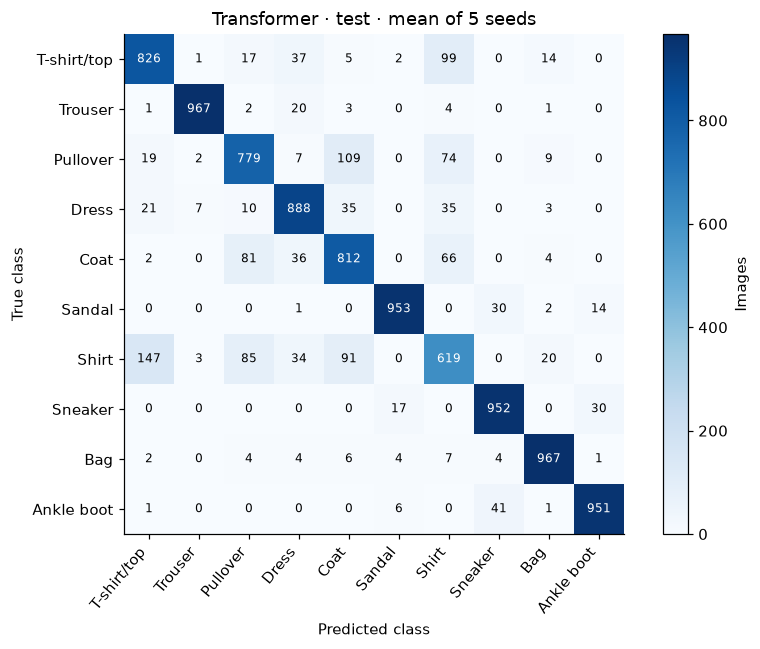

In [4]:
matrices = {name: np.array([confusion_matrix(predictions[name, s]["labels"], predictions[name, s]["predictions"],
                                             labels=range(10)) for s in SEEDS]) for name in MODELS}
for name, stack in matrices.items():
    matrix = np.rint(stack.mean(0)).astype(int)
    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.imshow(matrix, cmap="Blues", vmin=0)
    for true in range(10):
        for predicted in range(10):
            ax.text(predicted, true, matrix[true, predicted], ha="center", va="center",
                    color="white" if matrix[true, predicted] > matrix.max() / 2 else "black", fontsize=8)
    ax.set_xticks(range(10), NAMES, rotation=50, ha="right")
    ax.set_yticks(range(10), NAMES)
    ax.set(title=name + " · test · mean of 5 seeds", xlabel="Predicted class", ylabel="True class")
    fig.colorbar(image, ax=ax, label="Images")
    plt.tight_layout()
    plt.show()

In [5]:
rows = []
for name, stack in matrices.items():
    off = stack.copy()
    off[:, range(10), range(10)] = 0
    top_by_seed = [set(np.argsort(-m.ravel(), kind="stable")[:5].tolist()) for m in off]
    for position in np.argsort(-off.mean(0).ravel(), kind="stable")[:5]:
        true, predicted = divmod(int(position), 10)
        counts = off[:, true, predicted]
        rows.append({"model": name, "true": NAMES[true], "predicted": NAMES[predicted], "mean ± SD": pm(counts, 1),
                     "range": f"{counts.min()}–{counts.max()}", "class error rate": round(counts.mean() / 1000, 3),
                     "in seed's top five": f"{sum(int(position) in top for top in top_by_seed)}/5"})
pd.DataFrame(rows)

,model,true,predicted,mean ± SD,range,class error rate,in seed's top five
0,Linear,Pullover,Coat,136.0 ± 24.2,100–166,0.136,4/5
1,Linear,Shirt,T-shirt/top,130.4 ± 18.1,115–160,0.130,5/5
2,Linear,T-shirt/top,Shirt,118.2 ± 22.0,86–147,0.118,4/5
3,Linear,Pullover,Shirt,111.6 ± 23.0,88–145,0.112,3/5
4,Linear,Shirt,Pullover,105.6 ± 16.5,90–126,0.106,3/5
5,MLP,Shirt,T-shirt/top,116.6 ± 32.6,84–167,0.117,5/5
6,MLP,T-shirt/top,Shirt,101.2 ± 38.0,59–143,0.101,4/5
7,MLP,Pullover,Coat,94.2 ± 22.7,70–124,0.094,4/5
8,MLP,Coat,Pullover,76.8 ± 21.1,50–106,0.077,3/5
9,MLP,Shirt,Pullover,76.2 ± 6.4,67–82,0.076,3/5


**Observation.**
- All 25 listed directional errors are between the four upper-body classes. Shirt → T-shirt/top is in every seed's top five for every model (5/5).
- **The EDA ranking does not predict error size.** Pullover–Coat has the closest class means (0.088) and is Linear's largest error (**136.0**). But T-shirt/top–Shirt is only fourth closest (0.132), and Shirt → T-shirt/top is the largest error for the other four models.
- CNN's top five has no Pullover–Coat pair. All five CNN pairs include Shirt.
- **Direction depends on the seed.** Single directional counts vary much more than total errors: MLP's T-shirt/top → Shirt count ranges from **59 to 143**. The seed-42 bias towards T-shirt/top → Shirt in `02_results.ipynb` reverses in the five-seed means.

In [6]:
groups, stability = [], []
for name in MODELS:
    counts = []
    for s in SEEDS:
        true, pred = predictions[name, s]["labels"], predictions[name, s]["predictions"]
        wrong = true != pred
        upper = wrong & np.isin(true, UPPER_BODY) & np.isin(pred, UPPER_BODY)
        shoes = wrong & np.isin(true, FOOTWEAR) & np.isin(pred, FOOTWEAR)
        confident = wrong & (predictions[name, s]["probabilities"].max(axis=1) >= 0.9)
        counts.append([wrong.sum(), upper.sum(), shoes.sum(), (wrong & ~upper & ~shoes).sum(), confident.sum()])
    counts = np.array(counts)
    groups.append({"model": name, **{key: f"{pm(counts[:, i], 0)} ({counts[:, i].mean() / counts[:, 0].mean():.1%})"
                                     for i, key in enumerate(["all errors", "upper-body", "footwear", "other", "confident (p >= 0.9)"])}})
    # an image is a stable error when every seed misclassifies it
    votes = np.array([predictions[name, s]["labels"] != predictions[name, s]["predictions"] for s in SEEDS]).sum(0)
    stable = votes == len(SEEDS)
    stability.append({"model": name, "mean errors per seed": counts[:, 0].mean(), "wrong in >= 1 seed": (votes > 0).sum(),
                      "wrong in all 5 seeds": stable.sum(), "all-5 upper-body images": (stable & np.isin(test_labels, UPPER_BODY)).sum()})
display(pd.DataFrame(groups).set_index("model"))
display(pd.DataFrame(stability).set_index("model"))
everywhere = np.array([[predictions[name, s]["labels"] != predictions[name, s]["predictions"] for s in SEEDS] for name in MODELS]).all((0, 1))
print("Wrong in all 25 runs:", everywhere.sum(), dict(zip(NAMES, np.bincount(test_labels[everywhere], minlength=10))))

,all errors,upper-body,footwear,other,confident (p >= 0.9)
model,,,,,
Linear,1583 ± 8 (100.0%),939 ± 20 (59.3%),196 ± 8 (12.4%),449 ± 21 (28.3%),158 ± 9 (10.0%)
MLP,1123 ± 26 (100.0%),706 ± 15 (62.8%),131 ± 13 (11.6%),287 ± 14 (25.5%),259 ± 43 (23.1%)
CNN,874 ± 28 (100.0%),568 ± 21 (65.0%),89 ± 14 (10.2%),217 ± 10 (24.8%),220 ± 32 (25.1%)
LSTM,1189 ± 25 (100.0%),757 ± 20 (63.6%),114 ± 14 (9.6%),318 ± 5 (26.8%),158 ± 25 (13.3%)
Transformer,1285 ± 39 (100.0%),794 ± 29 (61.7%),139 ± 7 (10.8%),353 ± 20 (27.5%),134 ± 12 (10.4%)


,mean errors per seed,wrong in >= 1 seed,wrong in all 5 seeds,all-5 upper-body images
model,,,,
Linear,1583.4,2007,1175,860
MLP,1123.4,1836,559,421
CNN,874.4,1642,318,242
LSTM,1189.4,1962,595,450
Transformer,1285.2,2260,512,391


Wrong in all 25 runs: 146 {'T-shirt/top': np.int64(19), 'Trouser': np.int64(3), 'Pullover': np.int64(35), 'Dress': np.int64(13), 'Coat': np.int64(15), 'Sandal': np.int64(0), 'Shirt': np.int64(48), 'Sneaker': np.int64(2), 'Bag': np.int64(3), 'Ankle boot': np.int64(8)}


**Observation.**
- Upper-body confusions are **59.3–65.0%** of errors for every model. Footwear confusions are only 9.6–12.4%, which matches the smaller sandal–sneaker mixing in the EDA t-SNE.
- Confident errors (p ≥ 0.9) are 25.1% of CNN errors and 23.1% of MLP errors, against 10.0–13.3% for Linear, LSTM and Transformer.
- Linear repeats most of its errors: **1175** of about 1583 per seed are wrong in all 5 seeds. Its convex loss is the likely cause; we did not test this. For CNN, only 318 of about 874 repeat.
- **146 test images** are wrong in all 25 runs. Shirt (48) and Pullover (35) lead, and no Sandal is in this set. These images are likely ambiguous in the image itself, not an artefact of one model.

In [7]:
ids = [5806, 2856, 6926, 9574, 2506, 9133, 8292, 7584, 2914, 12, 21, 23, 25, 32, 4167, 5167, 8420]
pd.DataFrame([{"test ID": i, "true": NAMES[test_labels[i]],
               **{name: f"{sum(predictions[name, s]['predictions'][i] != test_labels[i] for s in SEEDS)}/5" for name in MODELS}}
              for i in ids]).set_index("test ID")

,true,Linear,MLP,CNN,LSTM,Transformer
test ID,,,,,,
5806,Shirt,5/5,5/5,5/5,5/5,5/5
2856,Shirt,5/5,5/5,5/5,5/5,5/5
6926,T-shirt/top,5/5,5/5,5/5,5/5,5/5
9574,Pullover,5/5,5/5,5/5,5/5,5/5
2506,T-shirt/top,5/5,5/5,5/5,5/5,5/5
9133,Shirt,5/5,5/5,5/5,5/5,5/5
8292,Sandal,5/5,5/5,5/5,3/5,5/5
7584,Sandal,0/5,3/5,4/5,4/5,1/5
2914,Sneaker,5/5,5/5,5/5,5/5,5/5


**Observation.**
- Six images are wrong for every model in every seed (5/5 everywhere). These are the six most confident CNN upper-body errors in the seed-42 galleries (#5806 … #9133). Ankle boot #23 and Sneaker #2914 are also wrong everywhere.
- These are properties of the images, consistent with the upper-body mixing and the sandal–sneaker mixing in the EDA t-SNE.
- Other gallery errors are seed noise. CNN misclassifies #12, #21 and #32 in only 2/5 seeds, and Dress #4167 and T-shirt/top #8420 are wrong in at most 1/5 seeds for any model.
- A single-seed gallery mixes both kinds of error, so it is not enough to tell them apart.

## 2. Robustness evaluation (extension)

- **Question:** does the inductive bias of each representation change how a model fails when test images change?
- **Hypothesis:** CNN tolerates small shifts better than flattened-input models; LSTM, which reads rows in order, tolerates vertical shifts better than horizontal shifts.
- **Fixed factors:** the 25 checkpoints and their training-split normalization. Noise and squares use fixed random seeds, so every model and seed sees the same images.
- **Metric:** test macro-F1, mean ± SD over seeds; drop from the clean score paired by seed. Shift scores average the four directions.

**Why noise?** The EDA shows that 50.2143% of all training pixels are exactly 0: in training, the background is always black. Noise turns it into grey speckle that no model has seen. It also tests the inductive bias: a 3 × 3 filter or a 4 × 4 patch sees only 9 or 16 pixels, while a dense layer sums all 784.

A **corruption** is a fixed change to the pixels of a test image before the model sees it. `x(i, j)` is the pixel in row `i`, column `j`, scaled to [0, 1] (background is 0). The corrupted image `x'` is then normalized like a clean image.

| Corruption | Rule for each pixel | Levels | What it imitates |
|---|---|---|---|
| Noise | `x' = clip(x + ε, 0, 1)`, `ε ~ N(0, σ²)` drawn independently per pixel | σ = 0.05, 0.10, 0.20 (13, 26, 51 of 255 grey levels) | Sensor noise; the black background becomes grey speckle |
| Shift | `x'(i, j) = x(i − dy, j − dx)`; pixels entering from outside are 0 | 1, 2, 3 pixels up, down, left, right | A garment that is not centred |
| Occlusion | `x' = 0` inside one k × k square at a random position | k = 8 (8% of the image), 12 (18%) | Part of the garment hidden |
| Contrast | `x' = c · x` | c = 0.75, 0.5 | A darker photo; the background stays 0 |

In [8]:
def shift(images, rows, columns):
    # empty pixels take the background value 0
    moved = np.zeros_like(images)
    source = images[:, max(0, -rows):28 - max(0, rows), max(0, -columns):28 - max(0, columns)]
    moved[:, max(0, rows):max(0, rows) + source.shape[1], max(0, columns):max(0, columns) + source.shape[2]] = source
    return moved

def occlude(images, size, seed=1):
    rng = np.random.default_rng(seed)
    tops, lefts = rng.integers(0, 29 - size, len(images)), rng.integers(0, 29 - size, len(images))
    covered = images.copy()
    for image, top, left in zip(covered, tops, lefts):
        image[top:top + size, left:left + size] = 0
    return covered

corrupted = [("clean", 0, "none", pixels)]
for sigma in (0.05, 0.10, 0.20):
    noise = np.random.default_rng(0).normal(0, sigma, pixels.shape).astype(np.float32)
    corrupted.append(("noise", sigma, "none", np.clip(pixels + noise, 0, 1)))
for step in (1, 2, 3):
    for direction, (rows, columns) in {"up": (-step, 0), "down": (step, 0), "left": (0, -step), "right": (0, step)}.items():
        corrupted.append(("shift", step, direction, shift(pixels, rows, columns)))
for size in (8, 12):
    corrupted.append(("occlusion", size, "none", occlude(pixels, size)))
for factor in (0.75, 0.5):
    corrupted.append(("contrast", factor, "none", pixels * np.float32(factor)))

AXIS = {"up": "vertical", "down": "vertical", "left": "horizontal", "right": "horizontal"}

SCORES = ROOT / "outputs" / "robustness_scores.csv"

def corruption_scores(names):
    # scores are saved once; later runs only evaluate models that are not in the file
    saved = pd.read_csv(SCORES) if SCORES.exists() else pd.DataFrame(columns=["model"])
    rows = []
    for name in [n for n in names if n not in set(saved["model"])]:
        for seed in SEEDS:
            model, mean, std = load_model(name, seed)
            for kind, level, direction, images in corrupted:
                with torch.inference_mode():
                    pred = torch.cat([model(batch).argmax(1) for batch in normalize(images, mean, std).split(1000)]).numpy()
                rows.append({"model": name, "seed": seed, "corruption": kind, "level": level, "direction": direction,
                             "axis": AXIS.get(direction, "none"), "accuracy": 100 * accuracy_score(test_labels, pred),
                             "macro_f1": 100 * f1_score(test_labels, pred, labels=range(10), average="macro", zero_division=0)})
            # the clean pass must reproduce evaluate.py before corrupted scores are trusted
            if abs(rows[-len(corrupted)]["macro_f1"] - 100 * runs[name, seed]["test"]["macro_f1"]) > 1e-4:
                raise ValueError(f"clean macro-F1 differs from metrics.json: {name} seed {seed}")
    if rows:
        saved = pd.concat([saved, pd.DataFrame(rows)], ignore_index=True)
        saved.to_csv(SCORES, index=False)
    return saved[saved["model"].isin(names)].reset_index(drop=True)

robust = corruption_scores(MODELS)
print("Loaded", len(robust), "model × seed × corruption cases; every clean score matched metrics.json when it was computed")

Loaded 500 model × seed × corruption cases; every clean score matched metrics.json when it was computed


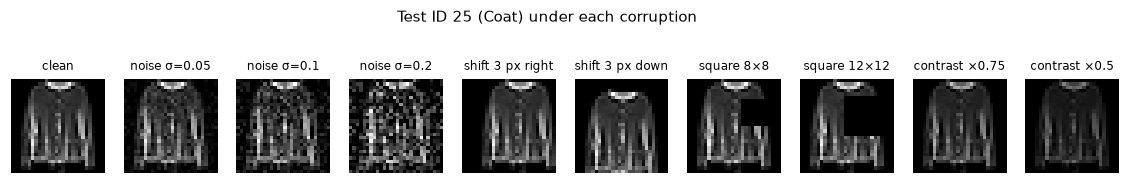

In [9]:
# one test image under every corruption
EXAMPLE = 25
shown = [("clean", 0, "none"), ("noise", 0.05, "none"), ("noise", 0.10, "none"), ("noise", 0.20, "none"),
         ("shift", 3, "right"), ("shift", 3, "down"), ("occlusion", 8, "none"), ("occlusion", 12, "none"),
         ("contrast", 0.75, "none"), ("contrast", 0.5, "none")]
lookup = {(kind, level, direction): images for kind, level, direction, images in corrupted}
fig, axes = plt.subplots(1, len(shown), figsize=(13, 1.9))
for ax, (kind, level, direction) in zip(axes, shown):
    ax.imshow(lookup[kind, level, direction][EXAMPLE], cmap="gray", vmin=0, vmax=1)
    label = {"clean": "clean", "noise": f"noise σ={level}", "shift": f"shift 3 px {direction}",
             "occlusion": f"square {level}×{level}", "contrast": f"contrast ×{level}"}[kind]
    ax.set_title(label, fontsize=8)
    ax.axis("off")
fig.suptitle(f"Test ID {EXAMPLE} ({NAMES[test_labels[EXAMPLE]]}) under each corruption", fontsize=10, y=1.05)
plt.show()

In [10]:
per_seed = robust.groupby(["model", "seed", "corruption", "level"], sort=False)["macro_f1"].mean().reset_index()
clean = per_seed[per_seed["corruption"] == "clean"].set_index(["model", "seed"])["macro_f1"]
per_seed["drop"] = clean.loc[list(zip(per_seed["model"], per_seed["seed"]))].to_numpy() - per_seed["macro_f1"]
scores = per_seed.pivot_table(index=["corruption", "level"], columns="model", values="macro_f1", aggfunc=list, sort=False)[MODELS]
display(scores.map(pm))
best = per_seed.pivot_table(index=["corruption", "level", "seed"], columns="model", values="macro_f1", sort=False).idxmax(axis=1)
display(best.groupby(level=[0, 1], sort=False).agg(lambda winners: ", ".join(f"{m} {n}/5" for m, n in winners.value_counts().items())).rename("best model per seed"))

model                   Linear           MLP           CNN          LSTM  \
corruption level                                                           
clean      0.00   84.15 ± 0.11  88.77 ± 0.23  91.27 ± 0.27  88.10 ± 0.21   
noise      0.05   83.76 ± 0.09  88.44 ± 0.23  89.58 ± 0.64  87.79 ± 0.24   
           0.10   82.85 ± 0.13  87.76 ± 0.21  84.47 ± 1.37  86.62 ± 0.44   
           0.20   80.22 ± 0.64  85.21 ± 0.28  65.89 ± 3.66  77.28 ± 2.98   
shift      1.00   76.00 ± 0.23  81.96 ± 0.23  88.56 ± 0.18  82.92 ± 0.78   
           2.00   59.79 ± 0.55  65.06 ± 0.98  81.08 ± 0.84  64.64 ± 1.10   
           3.00   42.85 ± 0.82  47.41 ± 1.62  67.38 ± 1.76  51.95 ± 1.32   
occlusion  8.00   76.91 ± 0.22  79.90 ± 0.46  83.45 ± 0.78  77.23 ± 0.63   
           12.00  66.19 ± 0.31  67.20 ± 1.29  72.85 ± 1.75  62.70 ± 1.44   
contrast   0.75   83.05 ± 0.37  87.93 ± 0.33  90.38 ± 0.30  86.61 ± 0.38   
           0.50   73.37 ± 1.04  81.93 ± 1.63  86.66 ± 1.17  80.44 ± 0.89   

model              Transformer  
corruption level                
clean      0.00   87.06 ± 0.36  
noise      0.05   86.07 ± 0.28  
           0.10   82.41 ± 0.59  
           0.20   59.88 ± 4.24  
shift      1.00   81.38 ± 1.24  
           2.00   68.52 ± 2.34  
           3.00   55.51 ± 2.11  
occlusion  8.00   73.17 ± 2.01  
           12.00  51.27 ± 4.01  
contrast   0.75   86.62 ± 0.55  
           0.50   83.44 ± 0.41

corruption  level
clean       0.00     CNN 5/5
noise       0.05     CNN 5/5
            0.10     MLP 5/5
            0.20     MLP 5/5
shift       1.00     CNN 5/5
            2.00     CNN 5/5
            3.00     CNN 5/5
occlusion   8.00     CNN 5/5
            12.00    CNN 5/5
contrast    0.75     CNN 5/5
            0.50     CNN 5/5
Name: best model per seed, dtype: str

In [11]:
strongest = per_seed[per_seed[["corruption", "level"]].apply(tuple, axis=1).isin([("noise", 0.2), ("shift", 2), ("occlusion", 12), ("contrast", 0.5)])]
display(strongest.pivot_table(index=["corruption", "level"], columns="model", values="drop", sort=False)[MODELS].round(2))
axis = robust[robust["corruption"] == "shift"].assign(axis=lambda d: d["direction"].map({"up": "vertical", "down": "vertical", "left": "horizontal", "right": "horizontal"}))
axis.groupby(["level", "axis", "model"])["macro_f1"].mean().unstack("model")[MODELS].round(2)

,model,Linear,MLP,CNN,LSTM,Transformer
corruption,level,,,,,
noise,0.2,3.92,3.56,25.38,10.82,27.18
shift,2.0,24.35,23.71,10.18,23.46,18.54
occlusion,12.0,17.95,21.56,18.41,25.41,35.79
contrast,0.5,10.77,6.84,4.61,7.66,3.62


model             Linear    MLP    CNN   LSTM  Transformer
level axis                                                
1.0   horizontal   74.67  80.88  88.58  80.27        80.62
      vertical     77.33  83.04  88.55  85.57        82.15
2.0   horizontal   51.92  57.97  79.74  48.90        62.70
      vertical     67.66  72.15  82.42  80.39        74.34
3.0   horizontal   29.18  34.97  58.86  27.93        44.11
      vertical     56.52  59.85  75.90  75.96        66.92

**Observation.**
- **CNN is the most robust model** for shifts, occlusion and reduced contrast in all five seeds.
- **Noise reverses the ranking.** From σ = 0.10, MLP is best in all five seeds (87.76 vs. 84.47 for CNN). At σ = 0.20, Transformer loses **27.18** points and CNN 25.38, but Linear and MLP lose less than 4. About half of the training pixels are exactly 0 (EDA: 50.2143%). Noise turns this background into grey speckle that the models never saw. A 3 × 3 filter or a 4 × 4 patch may react to local speckle, while a dense layer averages over all 784 pixels. This is not tested.
- **Shifts hurt flattened inputs.** A 2-pixel shift costs Linear 24.35, MLP 23.71 and LSTM 23.46 points, but CNN only 10.18. The EDA mean image shows where clothing tends to occupy the frame. A model that ties each weight to one pixel position likely relies on that fixed position.
- **LSTM follows its row design.** A vertical 3-pixel shift only moves rows in the sequence and keeps **75.96%**, equal to CNN (75.90%). A horizontal shift changes every row vector and drops LSTM to **27.93%**, the lowest of all models.
- **Contrast hurts Linear most (10.77), Transformer least (3.62).** Halving contrast keeps the background at 0 but scales the garment. Linear's score is a weighted sum of raw intensities, so it likely shifts with brightness, which the EDA shows differs between classes. The layer normalization in the Transformer may remove the scale (not tested).
- **Transformer is the least stable.** It loses **35.79** points under 12 × 12 occlusion and has the largest seed SDs (up to 4.24).

## 3. Interpretability analysis (extension)

- **Occlusion sensitivity (all models):** 300 test images (30 per class, sampled with seed 0). A 4 × 4 patch is set to background at stride 2 (169 positions); each pixel's value is the mean drop in true-class probability over the patches that cover it.
- **LSTM row probe:** the trained classifier reads the hidden state after every row on the full test set; nothing is retrained.
- **Transformer attention:** attention weights of both layers are recomputed from the encoder, checked against `forward()`.

In [12]:
PATCH, STRIDE = 4, 2
CORNERS = [(top, left) for top in range(0, 28 - PATCH + 1, STRIDE) for left in range(0, 28 - PATCH + 1, STRIDE)]
COVERAGE = np.zeros((28, 28), np.float32)
for top, left in CORNERS:
    COVERAGE[top:top + PATCH, left:left + PATCH] += 1
# thirds of the image height: collar and shoulders, body, hem
BANDS = {"top": slice(0, 9), "middle": slice(9, 19), "bottom": slice(19, 28)}

def occlusion_maps(model, images, labels, mean, std):
    maps = np.zeros((len(images), 28, 28), np.float32)
    with torch.inference_mode():
        for index, (image, label) in enumerate(zip(images, labels)):
            covered = np.repeat(image[None], len(CORNERS) + 1, axis=0)
            for position, (top, left) in enumerate(CORNERS, start=1):
                covered[position, top:top + PATCH, left:left + PATCH] = 0
            probability = model(normalize(covered, mean, std)).softmax(1)[:, label].numpy()
            for (top, left), value in zip(CORNERS, probability[0] - probability[1:]):
                maps[index, top:top + PATCH, left:left + PATCH] += value
    return maps / COVERAGE

def map_statistics(maps):
    positive = np.clip(maps, 0, None)
    total = positive.sum((1, 2))
    keep = total > 0
    shares = {band: (positive[:, rows].sum((1, 2))[keep] / total[keep]).mean() for band, rows in BANDS.items()}
    ordered = -np.sort(-positive.reshape(len(maps), -1)[keep], axis=1)
    # share of the 784 pixels that holds half of the positive evidence
    half = (np.cumsum(ordered, axis=1) < 0.5 * total[keep, None]).sum(1) + 1
    return {**shares, "half_mass_pixels": (half / 784).mean()}

rng = np.random.default_rng(0)
sample = np.sort(np.concatenate([rng.choice(np.flatnonzero(test_labels == k), 30, replace=False) for k in range(10)]))
upper = np.isin(test_labels[sample], UPPER_BODY)
maps, stats = {}, []
for name in MODELS:
    for seed in SEEDS:
        model, mean, std = load_model(name, seed)
        maps[name, seed] = occlusion_maps(model, pixels[sample], test_labels[sample], mean, std)
        # half-mass uses all sampled images; band shares use upper-body garments
        stats.append({"model": name, "seed": seed, **map_statistics(maps[name, seed][upper]),
                      "half_mass_pixels": map_statistics(maps[name, seed])["half_mass_pixels"]})
stats = pd.DataFrame(stats)

agreement = {}
for name in MODELS:
    # a fully confident model gives a flat map, so correlation skips images flat in any seed
    flat = np.stack([maps[name, s].reshape(len(sample), -1).std(1) < 1e-6 for s in SEEDS]).any(0)
    pairs = [np.mean([np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(maps[name, s][~flat], maps[name, t][~flat])])
             for s, t in combinations(SEEDS, 2)]
    agreement[name] = {"seed agreement r": pm(pairs), "images": int((~flat).sum())}
table = pd.DataFrame(agreement).T
for column in ["half_mass_pixels", "top", "middle", "bottom"]:
    table[column + " (%)"] = stats.groupby("model")[column].apply(lambda v: pm(100 * v, 1))
table.loc[MODELS]

,seed agreement r,images,half_mass_pixels (%),top (%),middle (%),bottom (%)
Linear,0.97 ± 0.02,297,7.3 ± 0.2,43.3 ± 1.0,30.6 ± 0.8,26.1 ± 0.5
MLP,0.76 ± 0.02,247,5.3 ± 0.1,42.6 ± 0.7,26.6 ± 0.8,30.8 ± 0.7
CNN,0.56 ± 0.02,264,5.8 ± 0.3,32.4 ± 2.1,36.4 ± 2.9,31.2 ± 3.8
LSTM,0.57 ± 0.02,300,6.0 ± 0.2,44.9 ± 2.3,22.8 ± 1.5,32.3 ± 2.5
Transformer,0.46 ± 0.02,300,8.3 ± 0.3,36.0 ± 1.3,36.3 ± 1.6,27.7 ± 1.0


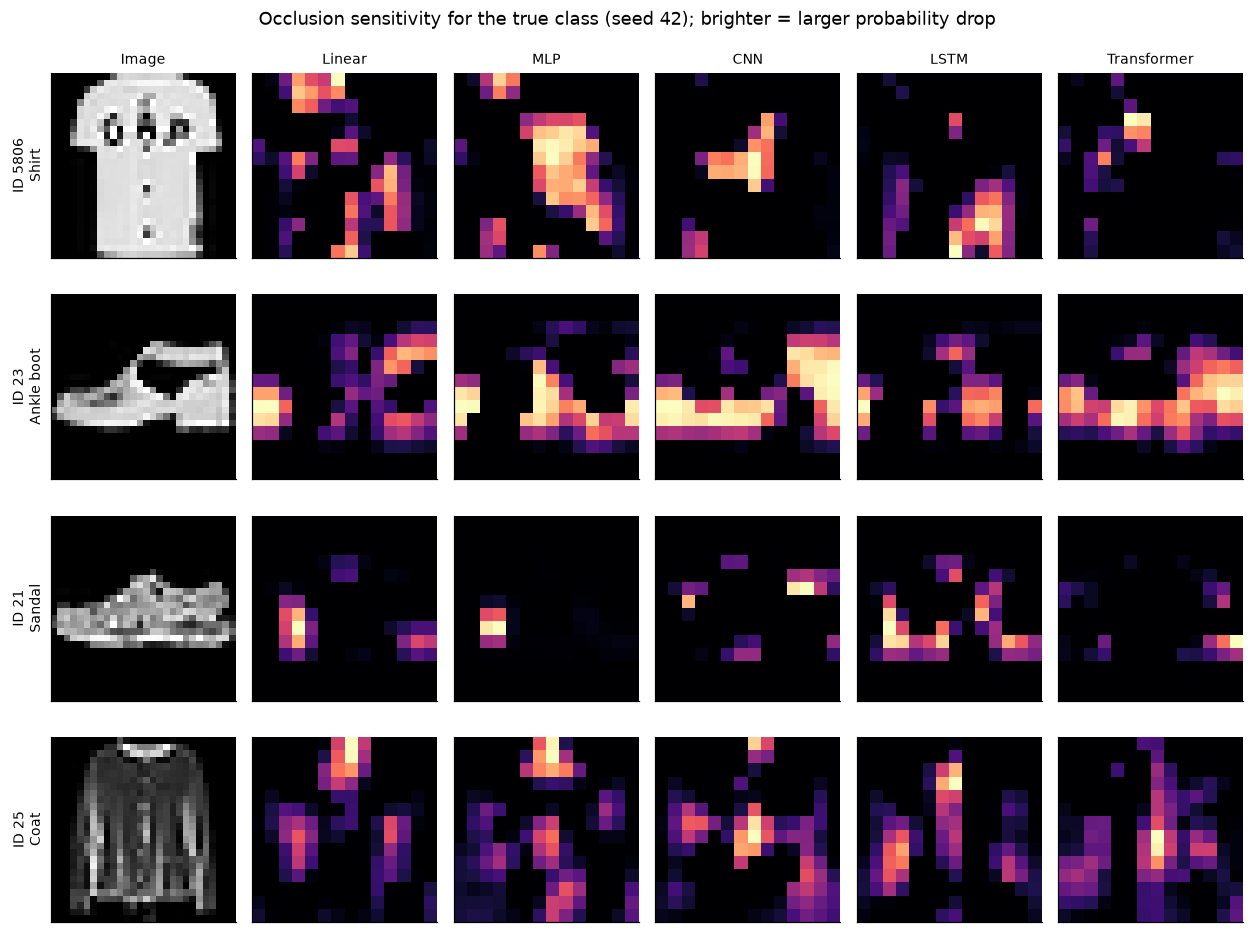

In [13]:
EXAMPLES = [5806, 23, 21, 25]   # test IDs discussed in 02_results.ipynb
fig, axes = plt.subplots(len(EXAMPLES), len(MODELS) + 1, figsize=(11.5, 2.2 * len(EXAMPLES)), squeeze=False)
for column, name in enumerate(["Image"] + MODELS):
    axes[0, column].set_title(name, fontsize=9)
    if column:
        model, mean, std = load_model(name, 42)
        example_maps = occlusion_maps(model, pixels[EXAMPLES], test_labels[EXAMPLES], mean, std)
    for row, image_id in enumerate(EXAMPLES):
        ax = axes[row, column]
        if column:
            ax.imshow(np.clip(example_maps[row], 0, None), cmap="magma", vmin=0)
        else:
            ax.imshow(test_images[image_id], cmap="gray", vmin=0, vmax=255)
            ax.set_ylabel(f"ID {image_id}\n{NAMES[test_labels[image_id]]}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("Occlusion sensitivity for the true class (seed 42); brighter = larger probability drop")
plt.tight_layout()
plt.show()

**Observation.**
- **Explanations are seed-dependent.** Linear maps are almost identical across seeds (r = **0.97**), but CNN, LSTM and Transformer agree only at r = 0.46–0.57. This matches section 1: Linear repeats its errors across seeds, while the other models change which errors they make. A map from one seed does not show the reasoning of the model family. MLP and CNN are fully confident on some images and give flat maps, so we excluded those images.
- **Upper-body evidence sits at the top.** For upper-body garments, Linear, MLP and LSTM put **42.6–44.9%** of their positive evidence in the top third (rows 0–8: collar, shoulders, sleeves). CNN puts 32.4% there and Transformer 36.0%. The EDA says necklines and openings separate the close upper-body pairs but may be subtle at 28 × 28. This may be one reason why Shirt stays the weakest class.
- **Concentration.** Half of the evidence lies in **5.3%** of the pixels for MLP and 8.3% for Transformer. Pixel-specific evidence is consistent with the large shift drops for flattened models in section 2.
- **Example.** For Ankle boot #23, which every run misclassifies, most models use the sole and the toe and heel edges. A sandal may also have these parts (not tested).

In [14]:
def row_probe(name):
    # the trained classifier reads the hidden state after every row, without retraining
    accuracy_by_row, final_row = [], []
    for seed in SEEDS:
        model, mean, std = load_model(name, seed)
        recurrent = model.lstm if hasattr(model, "lstm") else model.gru
        with torch.inference_mode():
            hidden = torch.cat([recurrent(batch.squeeze(1))[0] for batch in normalize(pixels, mean, std).split(1000)])
            pred = model.classifier(hidden).argmax(2).numpy()
        accuracy_by_row.append(100 * (pred == test_labels[:, None]).mean(0))
        # first row after which the prediction never changes again
        changed = pred != pred[:, -1:]
        stable_row = np.where(changed.any(1), 29 - np.argmax(changed[:, ::-1], axis=1), 1)
        final_row.append([np.median(stable_row[test_labels == k]) for k in range(10)])
    return np.array(accuracy_by_row), np.array(final_row)

accuracy_by_row, final_row = row_probe("LSTM")
display(pd.DataFrame({"accuracy (%)": [pm(accuracy_by_row[:, t - 1]) for t in (7, 14, 18, 21, 24, 26, 28)]},
                     index=pd.Index([7, 14, 18, 21, 24, 26, 28], name="rows read")))
pd.DataFrame({"row where prediction becomes final": final_row.mean(0).round(1),
              "seed range": [f"{lo:.0f}–{hi:.0f}" for lo, hi in zip(final_row.min(0), final_row.max(0))]},
             index=NAMES).sort_values("row where prediction becomes final")

,accuracy (%)
rows read,
7,20.78 ± 2.97
14,39.84 ± 2.09
18,54.91 ± 2.94
21,68.89 ± 2.17
24,82.59 ± 0.49
26,85.82 ± 0.31
28,88.11 ± 0.25


,row where prediction becomes final,seed range
Bag,10.8,8–13
Dress,11.2,7–13
Trouser,12.4,11–13
Sandal,16.2,10–20
Ankle boot,17.6,12–22
Coat,18.3,17–20
Pullover,19.6,18–21
T-shirt/top,20.0,19–21
Sneaker,22.2,21–23
Shirt,23.4,22–24


**Observation.**
- **LSTM decides late.** Accuracy is **39.84%** after 14 rows (half the image). It reaches its test accuracy (88.11%) only after row 28.
- Bag, Dress and Trouser become final after about 11–12 rows. Their outline is likely visible early, which agrees with the compact Trouser group in the EDA t-SNE.
- **Shirt becomes final last (row 23.4).** This matches section 1: Shirt is LSTM's weakest class, and Shirt → T-shirt/top is its largest error. The cue that separates Shirt may come only in the lower rows, but we did not test this.
- The classifier was trained only on the last hidden state, so early readings underestimate what the hidden state contains.

In [15]:
grid = np.stack(np.meshgrid(np.arange(7), np.arange(7), indexing="ij"), -1).reshape(49, 2)
distance = torch.from_numpy(np.linalg.norm(grid[:, None] - grid[None], axis=2)).float()
attention, rollout_bands = [], []
for seed in SEEDS:
    model, mean, std = load_model("Transformer", seed)
    images = normalize(pixels, mean, std)
    layer_stats, rollouts = [], []
    with torch.inference_mode():
        for batch in images.split(1000):
            hidden = model.projection(batch.unfold(2, 4, 4).unfold(3, 4, 4).reshape(len(batch), 49, 16)) + model.positions
            rollout, per_layer = torch.eye(49).repeat(len(batch), 1, 1), []
            for layer in model.encoder.layers:
                weights = layer.self_attn(hidden, hidden, hidden, need_weights=True, average_attn_weights=False)[1]
                # entropy 1.0 means uniform attention over all 49 patches
                entropy = -(weights * weights.clamp_min(1e-12).log()).sum(-1).mean(-1) / np.log(49)
                per_layer.append(torch.stack([(weights * distance).sum(-1).mean(-1), entropy]))
                # rollout adds the residual path and multiplies the layers
                mixed = 0.5 * weights.mean(1) + 0.5 * torch.eye(49)
                rollout = (mixed / mixed.sum(-1, keepdim=True)) @ rollout
                hidden = layer(hidden)
            if not torch.allclose(model.classifier(hidden.mean(1)), model(batch), atol=1e-5):
                raise ValueError("manual Transformer pass differs from forward()")
            layer_stats.append(torch.stack(per_layer))
            rollouts.append(rollout.mean(1).reshape(-1, 7, 7))
    layer_stats = torch.cat(layer_stats, 2).mean(2)   # [layer, statistic, head]
    rollouts = torch.cat(rollouts)
    for layer in range(2):
        attention.append({"seed": seed, "layer": layer + 1, "distance": layer_stats[layer, 0].mean().item(),
                          "entropy": layer_stats[layer, 1].mean().item(), "lowest head entropy": layer_stats[layer, 1].min().item()})
    rollout_bands.append([100 * rollouts[:, rows].sum((1, 2)).mean().item() for rows in (slice(0, 2), slice(2, 5), slice(5, 7))])
attention = pd.DataFrame(attention)
display(attention.groupby("layer").agg(distance=("distance", pm), entropy=("entropy", lambda v: pm(v, 3)),
                                       lowest_head_entropy=("lowest head entropy", "mean")).assign(uniform_distance=distance.mean().item()).round(3))
rollout_bands = np.array(rollout_bands)
pd.DataFrame({"rollout weight (%)": [pm(rollout_bands[:, i], 1) for i in range(3)], "area share (%)": [28.6, 42.9, 28.6]},
             index=["top 2 patch rows", "middle 3", "bottom 2"])

,distance,entropy,lowest_head_entropy,uniform_distance
layer,,,,
1,3.57 ± 0.04,0.870 ± 0.023,0.819,3.609
2,3.63 ± 0.05,0.488 ± 0.027,0.409,3.609


,rollout weight (%),area share (%)
top 2 patch rows,30.5 ± 0.8,28.6
middle 3,41.4 ± 0.5,42.9
bottom 2,28.1 ± 0.6,28.6


**Observation.**
- Layer 1 attention is close to uniform (entropy **0.870**). Layer 2 is more selective (0.488) but not local: its mean distance (3.63 patches) equals that of uniform attention (3.609).
- Rollout gives each band almost its area share (top 30.5% vs. 28.6%). This agrees with the occlusion maps, where Transformer puts 36.0% of its evidence in the top third, below Linear, MLP and LSTM.
- The Transformer did not learn the locality that CNN has by design. Its mean-pooled output is close to an average of patch features.
- **Link to section 2.** Near-uniform mixing means one corrupted patch can affect all patches. This may explain the large drops under noise (27.18) and 12 × 12 occlusion (35.79). It may also explain the low seed agreement (r = 0.46). None of these links is tested.

## 4. LSTM vs GRU (extension)

GRU removes the LSTM cell and keeps one hidden state. A reset gate decides how much of the previous state enters the candidate; an update gate `u` blends them: `h_t = (1 − u_t) ⊙ h̃_t + u_t ⊙ h_{t−1}`. When `u ≈ 1` the state is copied forward, like the LSTM forget path (RNN slides, Sections 4–5). `models/gru.py` replaces `nn.LSTM` with `nn.GRU` and changes nothing else: 28 rows of 28 pixels, hidden size 64.

- **Hypothesis:** with 25% fewer parameters (18,698 vs. 24,714), GRU matches LSTM, and it shares LSTM's row-order robustness.
- **Note:** extension runs were trained while other jobs used the same CPU, so their training and inference times are not compared.

In [16]:
def seed_summary(names):
    rows = []
    for name in names:
        results = [runs[name, s] for s in SEEDS]
        test = [100 * r["test"]["macro_f1"] for r in results]
        rows.append({"model": name, "parameters": results[0]["parameters"],
                     "validation macro-F1 (%)": pm([100 * r["validation"]["macro_f1"] for r in results]),
                     "test macro-F1 (%)": pm(test), "median": round(float(np.median(test)), 2),
                     "selected epochs": ", ".join(str(r["best_epoch"]) for r in results)})
    return pd.DataFrame(rows).set_index("model")

def paired(first, second):
    # test macro-F1 difference for the same seed
    diff = np.array([100 * (runs[first, s]["test"]["macro_f1"] - runs[second, s]["test"]["macro_f1"]) for s in SEEDS])
    return {"comparison": f"{first} − {second}", "mean (pp)": round(diff.mean(), 2), "min (pp)": round(diff.min(), 2),
            "max (pp)": round(diff.max(), 2), "first better": f"{(diff > 0).sum()}/5"}

display(seed_summary(["LSTM", "GRU"]))
pd.DataFrame([paired("GRU", "LSTM")]).set_index("comparison")

,parameters,validation macro-F1 (%),test macro-F1 (%),median,selected epochs
model,,,,,
LSTM,24714,89.80 ± 0.11,88.10 ± 0.21,88.11,"13, 16, 15, 13, 14"
GRU,18698,90.32 ± 0.14,88.88 ± 0.20,88.81,"16, 16, 14, 15, 16"


,mean (pp),min (pp),max (pp),first better
comparison,,,,
GRU − LSTM,0.78,0.55,1.36,5/5


In [17]:
VIEW = [("clean", 0, "none", "clean"), ("noise", 0.2, "none", "noise σ=0.20"),
        ("shift", 2, "horizontal", "shift 2 px horizontal"), ("shift", 2, "vertical", "shift 2 px vertical"),
        ("occlusion", 12, "none", "square 12×12"), ("contrast", 0.5, "none", "contrast ×0.5")]

def robustness_view(data, names):
    # test macro-F1 (%) per condition, mean ± SD over seeds; shift directions are averaged within an axis
    table = {}
    for kind, level, axis, label in VIEW:
        selected = data[(data["corruption"] == kind) & np.isclose(data["level"], level) & (data["axis"] == axis)]
        per_seed = selected.groupby(["model", "seed"])["macro_f1"].mean()
        table[label] = {name: pm(per_seed[name].to_numpy()) for name in names}
    return pd.DataFrame(table)

extension_robust = corruption_scores(["GRU"])
robustness_view(pd.concat([robust, extension_robust]), ["LSTM", "GRU"])

,clean,noise σ=0.20,shift 2 px horizontal,shift 2 px vertical,square 12×12,contrast ×0.5
LSTM,88.10 ± 0.21,77.28 ± 2.98,48.90 ± 1.88,80.39 ± 0.46,62.70 ± 1.44,80.44 ± 0.89
GRU,88.88 ± 0.20,81.99 ± 0.91,53.00 ± 3.63,81.68 ± 0.26,63.50 ± 0.73,83.01 ± 0.93


In [18]:
gru_accuracy, gru_final_row = row_probe("GRU")
rows_read = [7, 14, 18, 21, 24, 28]
pd.DataFrame({"LSTM accuracy (%)": [pm(accuracy_by_row[:, t - 1]) for t in rows_read],
              "GRU accuracy (%)": [pm(gru_accuracy[:, t - 1]) for t in rows_read]},
             index=pd.Index(rows_read, name="rows read"))

,LSTM accuracy (%),GRU accuracy (%)
rows read,,
7,20.78 ± 2.97,19.37 ± 3.28
14,39.84 ± 2.09,41.39 ± 3.03
18,54.91 ± 2.94,58.21 ± 1.84
21,68.89 ± 2.17,73.16 ± 1.28
24,82.59 ± 0.49,83.22 ± 0.54
28,88.11 ± 0.25,88.96 ± 0.19


**Observation.**
- **GRU beats LSTM with fewer parameters.** GRU scores **88.88 ± 0.20** and LSTM **88.10 ± 0.21**. The gap is **+0.78 pp**, GRU is better in **5/5** seeds, and the smallest paired gap is 0.55 pp. The gap is larger than both seed SDs, so the difference is supported. GRU has **18,698** parameters and LSTM has 24,714. This rejects the "matches" part of the hypothesis in GRU's favour.
- **GRU may be under-trained.** GRU selects epoch **16 in 3/5** seeds, and LSTM does so in 1/5. GRU also has the higher validation score (90.32 vs. 89.80). One possible cause is that GRU optimizes faster under the fixed 16-epoch budget: the update gate can act as a gated skip (`u ≈ 1` copies `h`), which gives a short gradient path over 28 steps. This mechanism is not tested. The slides say that the winner is task- and dataset-dependent, so the result applies only to this setup.
- **GRU keeps LSTM's row-order asymmetry.** A 2-pixel vertical shift keeps **81.68 ± 0.26**, but a horizontal shift drops GRU to **53.00 ± 3.63**. LSTM shows the same pattern (80.39 vs. 48.90). A vertical shift moves rows in the sequence; a horizontal shift changes every row vector (section 2). The cell type does not remove this weakness.
- **GRU is a little more robust, with one exception.** The gaps over LSTM are larger than the seed SDs under noise σ = 0.20 (**81.99 ± 0.91** vs. 77.28 ± 2.98), horizontal shift, vertical shift and contrast ×0.5 (83.01 vs. 80.44). Under the 12 × 12 square (63.50 ± 0.73 vs. 62.70 ± 1.44), the gap is smaller than the SD, so it is not supported.
- **GRU also decides late, but builds evidence earlier.** After 7 rows, GRU and LSTM are equal (19.37 vs. 20.78). After 18 and 21 rows, GRU leads (**58.21 vs. 54.91**, **73.16 vs. 68.89**), and these gaps are larger than the SDs. At row 14 (41.39 vs. 39.84), the gap is smaller than the SD.

## 5. Representation ablation (extension)

The same architecture reads the same image cut in a different way. Everything else is fixed; the classes are in `models/lstm.py` and `models/transformer.py`.

| Model | Sequence | Tokens × size | Changed from |
|---|---|---|---|
| LSTMColumns | columns, left to right | 28 × 28 | LSTM (rows, top to bottom) |
| TransformerPatch7 | 7 × 7 patches | 16 × 49 | Transformer (4 × 4 patches, 49 × 16) |
| TransformerRows | rows | 28 × 28 | Transformer |

- **Prediction:** LSTMColumns reverses LSTM's shift asymmetry: strong under horizontal shifts, weak under vertical shifts.

In [19]:
display(seed_summary(["LSTM", "LSTMColumns", "Transformer", "TransformerPatch7", "TransformerRows"]))
pd.DataFrame([paired("LSTMColumns", "LSTM"), paired("TransformerPatch7", "Transformer"),
              paired("TransformerRows", "Transformer")]).set_index("comparison")

,parameters,validation macro-F1 (%),test macro-F1 (%),median,selected epochs
model,,,,,
LSTM,24714,89.80 ± 0.11,88.10 ± 0.21,88.11,"13, 16, 15, 13, 14"
LSTMColumns,24714,88.84 ± 0.22,87.36 ± 0.23,87.37,"16, 16, 15, 14, 15"
Transformer,19530,88.48 ± 0.33,87.06 ± 0.36,87.00,"16, 16, 15, 16, 16"
TransformerPatch7,19530,88.47 ± 0.43,86.80 ± 0.43,86.98,"15, 15, 16, 16, 15"
TransformerRows,19242,89.91 ± 0.29,88.44 ± 0.31,88.40,"15, 15, 13, 16, 14"


,mean (pp),min (pp),max (pp),first better
comparison,,,,
LSTMColumns − LSTM,-0.75,-1.26,-0.41,0/5
TransformerPatch7 − Transformer,-0.26,-1.07,0.38,2/5
TransformerRows − Transformer,1.38,0.59,1.92,5/5


In [20]:
representation_robust = corruption_scores(["LSTMColumns", "TransformerPatch7", "TransformerRows"])
robustness_view(pd.concat([robust, representation_robust]),
                ["LSTM", "LSTMColumns", "Transformer", "TransformerPatch7", "TransformerRows"])

,clean,noise σ=0.20,shift 2 px horizontal,shift 2 px vertical,square 12×12,contrast ×0.5
LSTM,88.10 ± 0.21,77.28 ± 2.98,48.90 ± 1.88,80.39 ± 0.46,62.70 ± 1.44,80.44 ± 0.89
LSTMColumns,87.36 ± 0.23,72.59 ± 2.46,80.74 ± 1.63,71.68 ± 1.14,54.72 ± 0.66,80.96 ± 0.61
Transformer,87.06 ± 0.36,59.88 ± 4.24,62.70 ± 3.40,74.34 ± 1.66,51.27 ± 4.01,83.44 ± 0.41
TransformerPatch7,86.80 ± 0.43,69.89 ± 1.26,54.96 ± 1.92,72.31 ± 1.13,64.98 ± 1.30,82.04 ± 1.84
TransformerRows,88.44 ± 0.31,78.62 ± 1.32,53.67 ± 0.54,79.54 ± 0.39,62.25 ± 2.12,83.95 ± 1.23


**Observation.**
- **Rows are better than columns for LSTM.** LSTMColumns scores **87.36 ± 0.23**, which is **−0.75 pp** below LSTM in **0/5** seeds. The gap is larger than the SDs, so the difference is supported. It also loses more under noise σ = 0.20 (72.59 vs. 77.28) and the 12 × 12 square (54.72 vs. 62.70). One likely cause is that a row is a full horizontal profile, such as sleeve width, the gap between trouser legs or a flat shoe sole (EDA: the two-leg silhouette of trousers, the horizontal silhouette of footwear). If garments are approximately left-right symmetric, a column sequence reads two near-copies of the same profile. Neither idea is tested.
- **The shift asymmetry reverses, as predicted.** LSTMColumns keeps **80.74 ± 1.63** under a 2-pixel horizontal shift but only **71.68 ± 1.14** under a vertical shift. LSTM gives 48.90 and 80.39. The cell, the parameters and the training are the same, so the **sequence direction**, not the cell type, decides which shift hurts. A shift along the sequence moves tokens in time; a shift across it changes every token. GRU (section 4) gives the same result from the other side.
- **Larger patches do not change clean accuracy, but they change robustness.** TransformerPatch7 is **−0.26 pp** (2/5 seeds, SD up to 0.43), so the clean difference is not supported. It is much more stable under noise (**69.89 ± 1.26** vs. 59.88 ± 4.24) and the 12 × 12 square (**64.98 ± 1.30** vs. 51.27 ± 4.01). It is weaker under horizontal shift (54.96 vs. 62.70). A 49-pixel token likely averages per-pixel noise better than a 16-pixel token. This mechanism is not tested.
- **Row tokens are the best Transformer input.** TransformerRows is **+1.38 pp** over Transformer in **5/5** seeds (**88.44 ± 0.31**), with fewer parameters (19,242). It is above LSTM (88.10 ± 0.21) by a gap that only just passes the criterion. About half of all training pixels are 0 (EDA), so many 4 × 4 patches contain mostly background, but each row token holds a full profile. Section 3 showed attention near uniform and a mean-pooled output, so the Transformer mostly averages its tokens. An average of informative row tokens is likely better than an average of mostly-background patch tokens. This is a hypothesis.
- **Row tokens also bring the row weakness.** TransformerRows is strong under noise (**78.62 ± 1.32**), vertical shift (**79.54 ± 0.39**) and the 12 × 12 square (62.25 vs. 51.27). Under horizontal shift, it falls to **53.67 ± 0.54**, close to LSTM (48.90) and below the 4 × 4 Transformer (62.70). The token geometry, not attention or recurrence, sets this trade-off. No representation here is robust on both shift axes; only CNN comes close (section 2).

## 6. Shift + noise augmentation (extension)

Section 2 showed two weaknesses: flattened models fail under shifts, CNN and Transformer fail under noise. `models/augmented.py` retrains all five models with one change: each **training** image is changed every time it is drawn. Validation, test and checkpoint selection use clean images.

| | Test-time noise (section 2) | Training-time augmentation (this section) |
|---|---|---|
| Shift | Fixed 1, 2 or 3 px in one direction | Always: random integer dy, dx in {−2, …, 2} px; 24 of 25 draws move the image |
| Noise rule | `x' = clip(x + ε, 0, 1)`, `ε ~ N(0, σ²)` per pixel | Same rule |
| Noise strength | σ = 0.05, 0.10, 0.20 | σ = 0.10 only |
| Which images get noise | Every test image | A random half of the training images |
| Randomness | One fixed draw (seed 0) | New draw every epoch, from the training seed |

- **Name:** this is shift + noise augmentation, not training with noise alone. The two changes are applied together, so their effects cannot be separated.
- **Question:** does augmentation remove the weaknesses, and what does it cost on clean test images?
- **Note:** σ = 0.10 is the training level; σ = 0.20 tests twice that level.

In [21]:
AUGMENTED = ["Augmented" + name for name in MODELS]
display(seed_summary(AUGMENTED))
pd.DataFrame([paired("Augmented" + name, name) for name in MODELS]).set_index("comparison")

,parameters,validation macro-F1 (%),test macro-F1 (%),median,selected epochs
model,,,,,
AugmentedLinear,7850,80.36 ± 0.15,78.49 ± 0.24,78.56,"15, 9, 16, 11, 16"
AugmentedMLP,203530,88.28 ± 0.13,86.78 ± 0.21,86.84,"16, 14, 15, 15, 15"
AugmentedCNN,105866,91.43 ± 0.32,90.35 ± 0.25,90.41,"16, 15, 15, 13, 16"
AugmentedLSTM,24714,87.91 ± 0.19,86.48 ± 0.46,86.63,"15, 16, 16, 12, 14"
AugmentedTransformer,19530,85.07 ± 0.63,84.03 ± 0.69,84.40,"16, 15, 16, 16, 16"


,mean (pp),min (pp),max (pp),first better
comparison,,,,
AugmentedLinear − Linear,-5.66,-5.98,-5.47,0/5
AugmentedMLP − MLP,-1.98,-2.37,-1.58,0/5
AugmentedCNN − CNN,-0.92,-1.17,-0.60,0/5
AugmentedLSTM − LSTM,-1.62,-2.27,-1.39,0/5
AugmentedTransformer − Transformer,-3.03,-3.95,-2.32,0/5


In [22]:
augmented_robust = corruption_scores(AUGMENTED)
robustness_view(pd.concat([robust, augmented_robust]), [n for name in MODELS for n in (name, "Augmented" + name)])

,clean,noise σ=0.20,shift 2 px horizontal,shift 2 px vertical,square 12×12,contrast ×0.5
Linear,84.15 ± 0.11,80.22 ± 0.64,51.92 ± 1.02,67.66 ± 0.44,66.19 ± 0.31,73.37 ± 1.04
AugmentedLinear,78.49 ± 0.24,74.92 ± 0.24,75.88 ± 0.36,74.86 ± 0.30,51.33 ± 0.51,57.77 ± 2.56
MLP,88.77 ± 0.23,85.21 ± 0.28,57.97 ± 1.69,72.15 ± 0.30,67.20 ± 1.29,81.93 ± 1.63
AugmentedMLP,86.78 ± 0.21,84.70 ± 0.14,85.76 ± 0.10,84.77 ± 0.30,61.56 ± 0.70,78.91 ± 1.77
CNN,91.27 ± 0.27,65.89 ± 3.66,79.74 ± 1.56,82.42 ± 0.43,72.85 ± 1.75,86.66 ± 1.17
AugmentedCNN,90.35 ± 0.25,82.70 ± 1.08,89.51 ± 0.02,89.05 ± 0.30,70.48 ± 0.31,83.59 ± 1.35
LSTM,88.10 ± 0.21,77.28 ± 2.98,48.90 ± 1.88,80.39 ± 0.46,62.70 ± 1.44,80.44 ± 0.89
AugmentedLSTM,86.48 ± 0.46,83.32 ± 0.88,85.51 ± 0.50,85.21 ± 0.55,58.63 ± 1.26,79.37 ± 0.54
Transformer,87.06 ± 0.36,59.88 ± 4.24,62.70 ± 3.40,74.34 ± 1.66,51.27 ± 4.01,83.44 ± 0.41
AugmentedTransformer,84.03 ± 0.69,76.91 ± 1.91,83.09 ± 0.74,82.27 ± 0.85,48.74 ± 3.65,79.30 ± 1.64


In [23]:
# clean and noisy test images, base and augmented model of each architecture
noise_view = pd.concat([robust, augmented_robust])
noise_view = noise_view[noise_view["corruption"].isin(["clean", "noise"])]
rows = []
for name in MODELS:
    for model in (name, "Augmented" + name):
        row = {"model": model}
        for level in (0, 0.05, 0.10, 0.20):
            scores = noise_view[(noise_view["model"] == model) & np.isclose(noise_view["level"], level)]
            label = "clean" if level == 0 else f"σ={level:.2f}"
            row[f"{label} accuracy"] = pm(scores["accuracy"].to_numpy())
            row[f"{label} macro-F1"] = pm(scores["macro_f1"].to_numpy())
        rows.append(row)
pd.DataFrame(rows).set_index("model")

,clean accuracy,clean macro-F1,σ=0.05 accuracy,σ=0.05 macro-F1,σ=0.10 accuracy,σ=0.10 macro-F1,σ=0.20 accuracy,σ=0.20 macro-F1
model,,,,,,,,
Linear,84.17 ± 0.08,84.15 ± 0.11,83.78 ± 0.09,83.76 ± 0.09,82.89 ± 0.14,82.85 ± 0.13,80.31 ± 0.61,80.22 ± 0.64
AugmentedLinear,78.56 ± 0.34,78.49 ± 0.24,78.12 ± 0.40,78.01 ± 0.25,77.38 ± 0.27,77.24 ± 0.11,75.16 ± 0.28,74.92 ± 0.24
MLP,88.77 ± 0.26,88.77 ± 0.23,88.45 ± 0.28,88.44 ± 0.23,87.77 ± 0.25,87.76 ± 0.21,85.23 ± 0.31,85.21 ± 0.28
AugmentedMLP,86.85 ± 0.15,86.78 ± 0.21,86.71 ± 0.16,86.63 ± 0.21,86.31 ± 0.13,86.23 ± 0.15,84.79 ± 0.09,84.70 ± 0.14
CNN,91.26 ± 0.28,91.27 ± 0.27,89.51 ± 0.61,89.58 ± 0.64,84.51 ± 1.02,84.47 ± 1.37,66.89 ± 3.68,65.89 ± 3.66
AugmentedCNN,90.36 ± 0.25,90.35 ± 0.25,89.96 ± 0.20,89.95 ± 0.19,88.89 ± 0.26,88.93 ± 0.25,82.40 ± 1.06,82.70 ± 1.08
LSTM,88.11 ± 0.25,88.10 ± 0.21,87.79 ± 0.29,87.79 ± 0.24,86.63 ± 0.52,86.62 ± 0.44,77.32 ± 3.05,77.28 ± 2.98
AugmentedLSTM,86.52 ± 0.43,86.48 ± 0.46,86.39 ± 0.46,86.35 ± 0.49,86.03 ± 0.48,85.99 ± 0.51,83.39 ± 0.87,83.32 ± 0.88
Transformer,87.15 ± 0.39,87.06 ± 0.36,86.12 ± 0.28,86.07 ± 0.28,82.37 ± 0.56,82.41 ± 0.59,59.60 ± 4.19,59.88 ± 4.24


**Observation.**
- **Augmentation costs clean accuracy in every seed.** Clean test macro-F1 falls for all five models in 5/5 seeds. CNN has the smallest cost (**−0.92** pp) and Linear the largest (**−5.66** pp). The other costs are LSTM −1.62, MLP −1.98 and Transformer −3.03.
- **The cost follows the inductive bias.** Convolution and pooling already tolerate small shifts, so CNN pays the least. Linear has one fixed weight for each pixel and cannot represent shift invariance, so it must spread one template over many positions. This mechanism was not tested.
- **The shift weakness is gone.** For a horizontal 2 px shift, LSTM goes from **48.90 to 85.51**, MLP from 57.97 to 85.76 and Linear from 51.92 to 75.88. AugmentedCNN keeps **89.51 ± 0.02** under a horizontal shift and 89.05 under a vertical shift, close to its clean 90.35. LSTM's row asymmetry also goes away: 85.51 horizontal vs. 85.21 vertical.
- **Noise robustness improves where it was weak.** At σ = 0.20, twice the training σ, CNN goes from **65.89 to 82.70**, Transformer from 59.88 to 76.91 and LSTM from 77.28 to 83.32. Linear (80.22 → 74.92) and MLP (85.21 → 84.70) were already robust to noise and lose a little.
- **Occlusion and contrast get worse for all five models.** With a 12 × 12 square, Linear goes from 66.19 to 51.33 and CNN from 72.85 to 70.48. With contrast ×0.5, Linear goes from **73.37 to 57.77** and CNN from 86.66 to 83.59. The gain is specific to the corruptions seen in training. Part of each fall comes from the lower clean score, but Linear's contrast fall is much larger than its clean fall.
- **Why contrast may get worse (not tested).** Training noise makes the background grey and shifts move the garment. The models may learn to treat faint pixels as noise, so a darkened garment can look like noise.
- **The value depends on the deployment.** The test set is clean, so the clean cost is real. The robustness gain matters only if real images are shifted or noisy. AugmentedCNN is still the best augmented model on clean images (90.35).
- **The 16-epoch budget may be too short.** 11 of 25 augmented runs select epoch 16, and AugmentedTransformer does so in 4 of 5 seeds. Part of the clean cost may come from the budget. This was not tested.
- **Note.** `metrics.json` for these runs records `"augmentation": None` because `train.fit` writes a fixed value. The real augmentation is the one in `models/augmented.py`.

## 7. Summary

| Question | Answer | Evidence (section) |
|---|---|---|
| Which model is best, and why? | CNN: **91.27 ± 0.27** macro-F1, best F1 in all ten classes, better than every other model in 5/5 seeds. It stays best at about 25k parameters (90.51, above the full MLP at 88.77). Its local filters, not its size, give the lead. | §1; `02_results` seed variability and matched-budget ablation |
| Which class is hardest? | Shirt is the weakest class in all 25 runs (F1 0.599 Linear to 0.751 CNN). Upper-body confusions are 59–65% of errors. **146 images** are wrong in all 25 runs, 48 of them Shirts: the difficulty is in the data, not in one model. | §1 |
| How do models fail under corruption? | CNN is the most robust under shift, occlusion and contrast in 5/5 seeds. Noise reverses the ranking: from σ = 0.10, MLP is best; at σ = 0.20, CNN and Transformer lose more than 25 pp. LSTM keeps 75.96 under a 3 px vertical shift but only 27.93 under a horizontal one. | §2 |
| What does interpretability show? | Explanations depend on the seed: Linear maps agree at r = 0.97, CNN, LSTM and Transformer only at 0.46–0.57. LSTM decides late (39.84% after 14 rows; Shirt fixed last, row 23.4). Transformer attention is not local (layer 2: 3.63 patches vs. 3.609 uniform). | §3 |
| Is GRU different from LSTM? | GRU is better by **+0.78 pp** in 5/5 seeds with 25% fewer parameters (18,698 vs. 24,714). It is equal to or better than LSTM under every corruption, e.g. noise σ = 0.20: 81.99 vs. 77.28. | §4 |
| Does the input representation matter? | Yes. Columns flip LSTM's asymmetry: horizontal 2 px 48.90 → 80.74, vertical 80.39 → 71.68. TransformerRows gains +1.38 pp in 5/5 seeds. TransformerPatch7 is level on clean images (−0.26, 2/5) but better under occlusion (64.98 vs. 51.27). | §5 |
| What does augmentation trade? | Clean macro-F1 falls in 5/5 seeds, by −0.92 (CNN) to −5.66 (Linear). Shift and noise robustness rise strongly (CNN noise 65.89 → 82.70). Occlusion and contrast ×0.5 get worse for all models. | §6 |

**What the EDA predicted and what it did not.** The EDA found the closest class means among Pullover, Coat and Shirt, and t-SNE mixed these classes. The models confirm this: upper-body errors dominate and Shirt is always the weakest class. But the most frequent error is Shirt → T-shirt/top, a pair that is only fourth closest in the EDA (RMS 0.132). The EDA did not test robustness, but two of its facts fit the failures: about half of all pixels are exactly 0, so noise changes a large area that is background in training; and the mean image shows a fixed region where clothing usually sits, which flattened models may rely on. These links are hypotheses and were not tested.

**Limitations.**
- All results come from one train/validation split, five seeds and a fixed 16-epoch budget. Transformer and many augmented runs select the last epoch, so they may be under-trained.
- The corruptions are synthetic and use fixed random seeds. The stated mechanisms are not tested, for example dense averaging against noise, non-local attention and the contrast loss after augmentation.